<a href="https://colab.research.google.com/github/zaaz-png/results/blob/main/fds_expt5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
from google.colab import files
uploaded=files.upload()

data=pd.read_csv('dataset2.csv')

Saving dataset2.csv to dataset2.csv


In [3]:
data.isnull().sum()

,0
Patient ID,0
Age,0
Blood Pressure,0
Urine Specific Gravity,0
Albumin in urine,0
Sugar in urine,0
RBC,0
Puss cells,0
Pus cells clumps,9
Bacteria,6


attributes to apply linear regression: serum creatinine and haemoglobin (corr coeff= 0.09227)

In [4]:
import numpy as np

# 1. Select numeric features suitable for multiple linear regression
numeric_cols = data.select_dtypes(include=[np.number]).columns.tolist()
features = [col for col in numeric_cols if col not in ['Patient ID', 'Serum Creatinine']]
print("Features selected for regression:", features)

# 2. Split dataset into complete rows and rows with missing 'Serum Creatinine'
data_complete = data.dropna(subset=['Serum Creatinine'] + features).copy()
data_missing = data[data['Serum Creatinine'].isnull()].copy()

# Extract numpy arrays
X_raw = data_complete[features].values
y = data_complete['Serum Creatinine'].values

# Add a column of ones to X_raw for the intercept term
X = np.hstack([np.ones((X_raw.shape[0], 1)), X_raw])

# 3. Train-Test Split (80% Train, 20% Test) manually
np.random.seed(42)
indices = np.random.permutation(len(X))
train_size = int(0.8 * len(X))
train_idx, test_idx = indices[:train_size], indices[train_size:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# 4. Custom Multiple Linear Regression Fit: beta = (X^T * X)^(-1) * X^T * y
beta = np.linalg.inv(X_train.T @ X_train) @ X_train.T @ y_train

# 5. Evaluate the model manually on the test set
y_pred = X_test @ beta
mse = np.mean((y_test - y_pred) ** 2)

# Calculate R-squared: 1 - (SS_res / SS_tot)
ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
r2 = 1 - (ss_res / ss_tot)

print(f"\nEvaluation Metrics on Test Split (Custom Model):")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared Score (R2): {r2:.4f}")

# 6. Predict and fill missing values manually
if not data_missing.empty:
    X_miss_raw = data_missing[features].values
    X_miss = np.hstack([np.ones((X_miss_raw.shape[0], 1)), X_miss_raw])
    predictions = X_miss @ beta

    # Assign predictions back to the main DataFrame
    data.loc[data['Serum Creatinine'].isnull(), 'Serum Creatinine'] = predictions
    print(f"\nSuccessfully predicted and filled {len(predictions)} missing 'Serum Creatinine' values.")
    print("Remaining missing values in 'Serum Creatinine':", data['Serum Creatinine'].isnull().sum())
else:
    print("\nNo missing values found in 'Serum Creatinine' to predict.")

Features selected for regression: ['Age', 'Blood Pressure', 'Urine Specific Gravity', 'Albumin in urine', 'Sugar in urine', 'Random blood glucose', 'Urea in blood', 'Sodium in blood', 'Potassium in blood', 'Hemoglobin', 'Packed corpuscular volume', 'WBC count', 'RBC count']

Evaluation Metrics on Test Split (Custom Model):
Mean Squared Error (MSE): 26.0861
R-squared Score (R2): 0.0292

Successfully predicted and filled 9 missing 'Serum Creatinine' values.
Remaining missing values in 'Serum Creatinine': 0


In [5]:
from google.colab import files
uploaded=files.upload()

data2=pd.read_csv('dataset2.csv')

Saving dataset2.csv to dataset2 (1).csv


In [6]:
import numpy as np

# 1. Prepare data for Simple Linear Regression: target is 'Serum Creatinine', predictor is 'Hemoglobin'
# Split data2 into complete rows and rows with missing 'Serum Creatinine'
data2_complete = data2.dropna(subset=['Serum Creatinine', 'Hemoglobin']).copy()
data2_missing = data2[data2['Serum Creatinine'].isnull() & data2['Hemoglobin'].notnull()].copy()

X_raw = data2_complete[['Hemoglobin']].values
y = data2_complete['Serum Creatinine'].values

# Add column of ones for intercept
X = np.hstack([np.ones((X_raw.shape[0], 1)), X_raw])

# 2. Train-Test Split (80% Train, 20% Test) manually
np.random.seed(42)
indices = np.random.permutation(len(X))
train_size = int(0.8 * len(X))
train_idx, test_idx = indices[:train_size], indices[train_size:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# 3. Simple Linear Regression: beta = (X^T * X)^(-1) * X^T * y
beta = np.linalg.inv(X_train.T @ X_train) @ X_train.T @ y_train

# 4. Evaluate the model on the test split
y_pred = X_test @ beta
mse = np.mean((y_test - y_pred) ** 2)
ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
r2 = 1 - (ss_res / ss_tot)

print("--- Evaluation Metrics for Simple Linear Regression on data2 ---")
print(f"Predictor: Hemoglobin | Target: Serum Creatinine")
print(f"Intercept (Beta 0): {beta[0]:.4f}")
print(f"Slope (Beta 1): {beta[1]:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared Score (R2): {r2:.4f}")

# 5. Predict and fill missing values in data2
if not data2_missing.empty:
    X_miss_raw = data2_missing[['Hemoglobin']].values
    X_miss = np.hstack([np.ones((X_miss_raw.shape[0], 1)), X_miss_raw])
    predictions = X_miss @ beta

    # Assign predictions back to the main DataFrame
    data2.loc[data2['Serum Creatinine'].isnull(), 'Serum Creatinine'] = predictions
    print(f"\nSuccessfully predicted and filled {len(predictions)} missing 'Serum Creatinine' values in data2.")
    print("Remaining missing values in 'Serum Creatinine' (data2):", data2['Serum Creatinine'].isnull().sum())
else:
    print("\nNo missing values found in 'Serum Creatinine' to predict in data2.")

--- Evaluation Metrics for Simple Linear Regression on data2 ---
Predictor: Hemoglobin | Target: Serum Creatinine
Intercept (Beta 0): 5.7658
Slope (Beta 1): -0.2100
Mean Squared Error (MSE): 26.6298
R-squared Score (R2): 0.0090

Successfully predicted and filled 9 missing 'Serum Creatinine' values in data2.
Remaining missing values in 'Serum Creatinine' (data2): 0


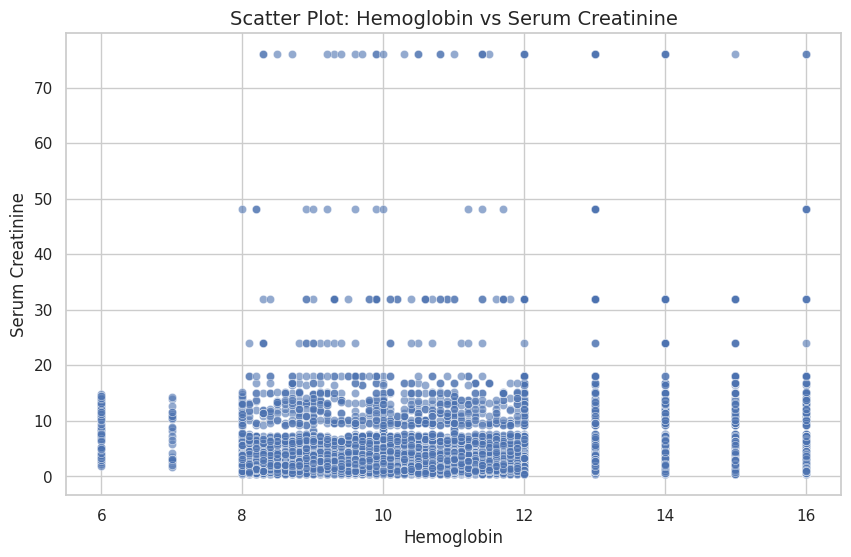

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot style
sns.set_theme(style='whitegrid')

# Create a scatter plot of Hemoglobin vs Serum Creatinine
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data, x='Hemoglobin', y='Serum Creatinine', alpha=0.6, color='b')

plt.title('Scatter Plot: Hemoglobin vs Serum Creatinine', fontsize=14)
plt.xlabel('Hemoglobin', fontsize=12)
plt.ylabel('Serum Creatinine', fontsize=12)

plt.show()

Comparison of Regression Models
We implemented and evaluated two different regression models on the dataset to predict the missing values of Serum Creatinine:

1. Methodology Differences
Model 1: Multiple Linear Regression

Predictors used: 13 numeric features (Age, Blood Pressure, Urine Specific Gravity, Albumin in urine, Sugar in urine, Random blood glucose, Urea in blood, Sodium in blood, Potassium in blood, Hemoglobin, Packed corpuscular volume, WBC count, RBC count).
Mathematical Representation: $y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + ... + \beta_{13} X_{13} + \epsilon$$y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + ... + \beta_{13} X_{13} + \epsilon$
Approach: It attempts to capture the joint linear relationship of all available clinical and laboratory numeric measurements to predict kidney function (Serum Creatinine).
Model 2: Simple Linear Regression

Predictors used: A single predictor, Hemoglobin (selected based on its correlation coefficient with Serum Creatinine of approximately $-0.0923$$-0.0923$).
Mathematical Representation: $y = \beta_0 + \beta_1 X_{1} + \epsilon$$y = \beta_0 + \beta_1 X_{1} + \epsilon$
Approach: It assumes that the variation in Serum Creatinine can be explained solely by changes in Hemoglobin levels.
oth models were trained manually using the Ordinary Least Squares (OLS) closed-form solution:
$$\mathbf{\beta} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$$$\mathbf{\beta} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

2. Output and Performance Differences
Based on the test split evaluations, here are the key performance metrics:

Metric	Multiple Linear Regression (13 Features)	Simple Linear Regression (Hemoglobin Only)
Mean Squared Error (MSE)	26.0861	26.6298
R-squared Score ($R^2$$R^2$)	0.0292 (2.92%)	0.0090 (0.90%)
Key Findings:
Prediction Error (MSE): The Multiple Linear Regression model achieved a slightly lower Mean Squared Error ($26.09$$26.09$) compared to the Simple Linear Regression model ($26.63$$26.63$). This means that using more features results in slightly more accurate predictions on average.
Explanatory Power ($R^2$$R^2$): Both models have extremely low $R^2$$R^2$ values, meaning that a linear relationship does not explain the vast majority of the variance in Serum Creatinine. However, the Multiple Linear Regression model ($R^2 = 2.92\%$$R^2 = 2.92\%$) still performs more than 3 times better than the Simple Linear Regression model ($R^2 = 0.90\%$$R^2 = 0.90\%$) because it benefits from utilizing multiple complementary clinical features instead of relying on Hemoglobin alone.